# Лабораторна робота № 4
## AI-підкріплена дата-аналітика у Jupyter
**Волошин Артем, ІС-31**

Я створив асистента для аналізу платежів мобільного застосунку. Pandas рахує числа,
а локальна мовна модель через Ollama пояснює результати, пропонує гіпотези та наступні перевірки.

Функції: `auto_eda`, `suggest_hypotheses`, `explain_metric_change`, `executive_summary`.
Повний код доступний у `analytics.py`, `assistant.py` та `prompts.py` поруч із ноутбуком.

**Запуск:** розпакувати весь комплект, встановити `requirements.txt`, відкрити цей файл у Jupyter.
За замовчуванням `MODE = "saved"`: показуються збережені справжні відповіді моделі.
Для нового AI-запуску виконати `ollama pull qwen2.5:7b`, запустити Ollama та встановити `MODE = "live"` нижче.
За `MODE = "compute"` виконуються лише розрахунки: це перевірка даних, а не демонстрація LLM.
Ключ API не потрібен. Перший запит може тривати довше через завантаження моделі в пам’ять.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from analytics import load_data, metrics, compare_periods, profile_dataframe, save_json
from assistant import (OllamaClient, SavedRunClient, auto_eda, suggest_hypotheses,
                       explain_metric_change, executive_summary, format_analysis)

ROOT = Path.cwd()
if not (ROOT / "data" / "payments.csv").exists():
    raise FileNotFoundError("Відкрий ноутбук із папки lab4, де є data та assistant.py.")
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
MODE = "saved"  # saved — збережене демо; live — нові запити; compute — лише Pandas
MODEL = "qwen2.5:7b"
if MODE not in {"saved", "live", "compute"}:
    raise ValueError("MODE має бути saved, live або compute")
client = (OllamaClient(model=MODEL, timeout=300, log_dir=RESULTS / "llm_runs") if MODE == "live"
          else SavedRunClient(model=MODEL, log_dir=RESULTS / "llm_runs") if MODE == "saved" else None)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
print("Режим:", MODE)

Режим: saved


## 1. Дані та перевірка об’єднання
Використовую надані CSV із третьої лабораторної: платежі, реєстрації та довідник країн.
Це навчальний набір, а не нові згенеровані дані. Платежі з’єдную з користувачами через `user_id`
із перевіркою `many_to_one`. Суми перевожу в цілі центи, щоб перевіряти підсумки без похибки float.
Код `NA` зберігаю як Намібію. Повні збіги платежів лише позначаю: без ID транзакції вони не обов’язково є помилкою.

In [2]:
users, payments, rejected, audit = load_data(ROOT / "data")
display(pd.DataFrame([
    {"Таблиця": "registrations", "Рядків": len(users)},
    {"Таблиця": "payments", "Рядків": len(payments)},
    {"Таблиця": "country_info_dict", "Рядків": len(pd.read_csv(ROOT / "data/country_info_dict.csv"))},
]))
display(pd.DataFrame([audit]).T.rename(columns={0:"Значення"}))
display(payments[["pay_dt", "amount_usd", "app", "country_code", "feature_type_id"]].head())
save_json(audit, RESULTS / "audit.json")

,Таблиця,Рядків
0,registrations,202382
1,payments,11330
2,country_info_dict,253


,Значення
raw_payments,11330
valid_payments,11330
rejected_payments,0
exact_payment_duplicates,0
payments_before_registration,0
missing_user_age,2


,pay_dt,amount_usd,app,country_code,feature_type_id
0,2024-04-05 19:16:14,7.49,android,FR,1
1,2024-04-05 19:16:36,17.99,android,FR,2
2,2024-04-05 03:19:55,6.05,ios,BR,1
3,2024-04-05 03:39:55,5.99,ios,US,1
4,2024-04-05 04:01:26,5.99,ios,UA,1


## 2. Автоматичний EDA
На вхід можна передати CSV або DataFrame. Профіль містить типи колонок, пропуски,
унікальні значення, повтори, розподіли та позначки за правилом IQR. Великий платіж за цим
правилом є кандидатом на перевірку, а не автоматично помилковим рядком.
LLM отримує агрегати; ідентифікатори користувачів до запиту не передаються.

,column,dtype,missing,missing_pct,unique
0,user_id,int64,0,0.0,7781
1,pay_dt,str,0,0.0,11297
2,amount_usd,float64,0,0.0,488
3,feature_type_id,int64,0,0.0,2


,kind,min,max,mean,median,q1,q3,nonfinite,iqr_flags
0,numeric,5.01,19.99,8.274455,5.99,5.99,6.9,0,2561


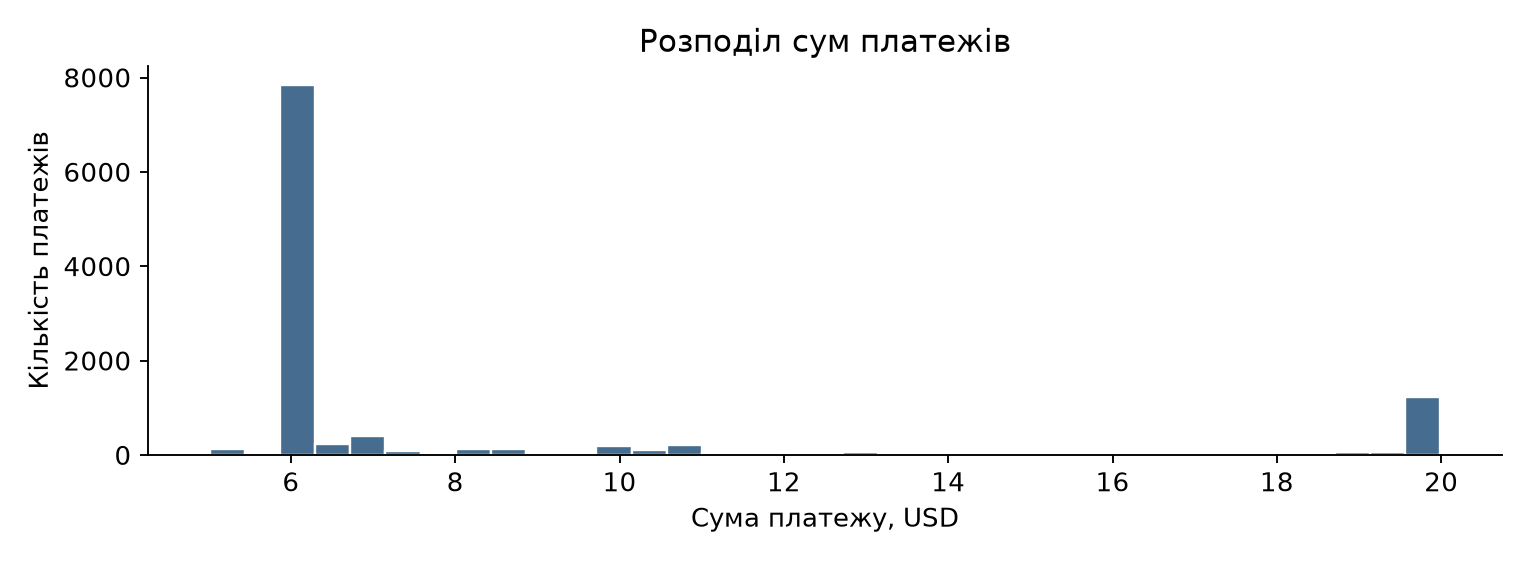

Модель: qwen2.5:7b | saved_validated

1. Кількість рядків
Спостереження: Даних достатньо для аналізу.
Гіпотеза / обмеження: Вибірка є представною для оцінки загального стану платників.
Перевірка: Порівняти кількість рядків з кількістю унікальних user_id.
  [F001] Кількість рядків: 11330 рядків

2. Медіана та середнє значення amount_usd
Спостереження: Середнє значення більше медіани, що може підказувати про викиди.
Гіпотеза / обмеження: Вибірка містить велику кількість виключно великих платежів.
Перевірка: Порівняти частку рядків з позначками IQR та кількість викидів.
  [F007] amount_usd: mean: 8.27 
  [F008] amount_usd: median: 5.99 
  [F010] amount_usd: iqr_flags: 2561 

3. Частка позначок IQR
Спостереження: 22.6% рядків мають позначки IQR.
Гіпотеза / обмеження: Вибірка містить значну кількість виключно великих платежів, що може супроводжуватися змінами у структурі платників.
Перевірка: Порівняти частку рядків з позначками IQR з кількістю викидів.
  [F011] amount_usd: частка позначок 

In [3]:
eda = auto_eda(ROOT / "data/payments.csv", client=client)
display(pd.DataFrame(eda["profile"]["columns"]))
distribution = eda["profile"]["distributions"]["amount_usd"]
display(pd.DataFrame([{k:v for k,v in distribution.items() if k != "histogram"}]))
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.hist(payments.amount_usd, bins=35, color="#466d8f", edgecolor="white")
ax.set(xlabel="Сума платежу, USD", ylabel="Кількість платежів", title="Розподіл сум платежів")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(RESULTS / "payment_distribution.png", dpi=170); plt.close(fig)
display(Image(filename=str(RESULTS / "payment_distribution.png")))
print(format_analysis(eda["analysis"]))
save_json(eda, RESULTS / f"eda_{MODE}.json")

**Моя оцінка EDA-відповіді.** Модель назвала вибірку репрезентативною лише за кількістю рядків.
Це не доведено: потрібна інформація про спосіб збирання даних. Також вислів про «виключно великі платежі»
надто сильний. Правило IQR позначило частину платежів, але не встановило помилку чи зміну складу платників.
Корисний результат тут — сам профіль і перелік кандидатів на перевірку. Їх варто зіставити з тарифами.

## 3. Базові метрики
Початкове вікно — 5 квітня–10 травня включно. Дані за 11 травня неповні,
тому їх не включаю до базового порівняння. Середній платіж — виручка, поділена на число платежів;
це не ARPPU і не середній дохід на всіх користувачів.

,start,end,days,payments,paying_users,revenue_usd,avg_payment_usd
0,2024-04-05,2024-05-10,36,11159,7664,92240.4,8.266


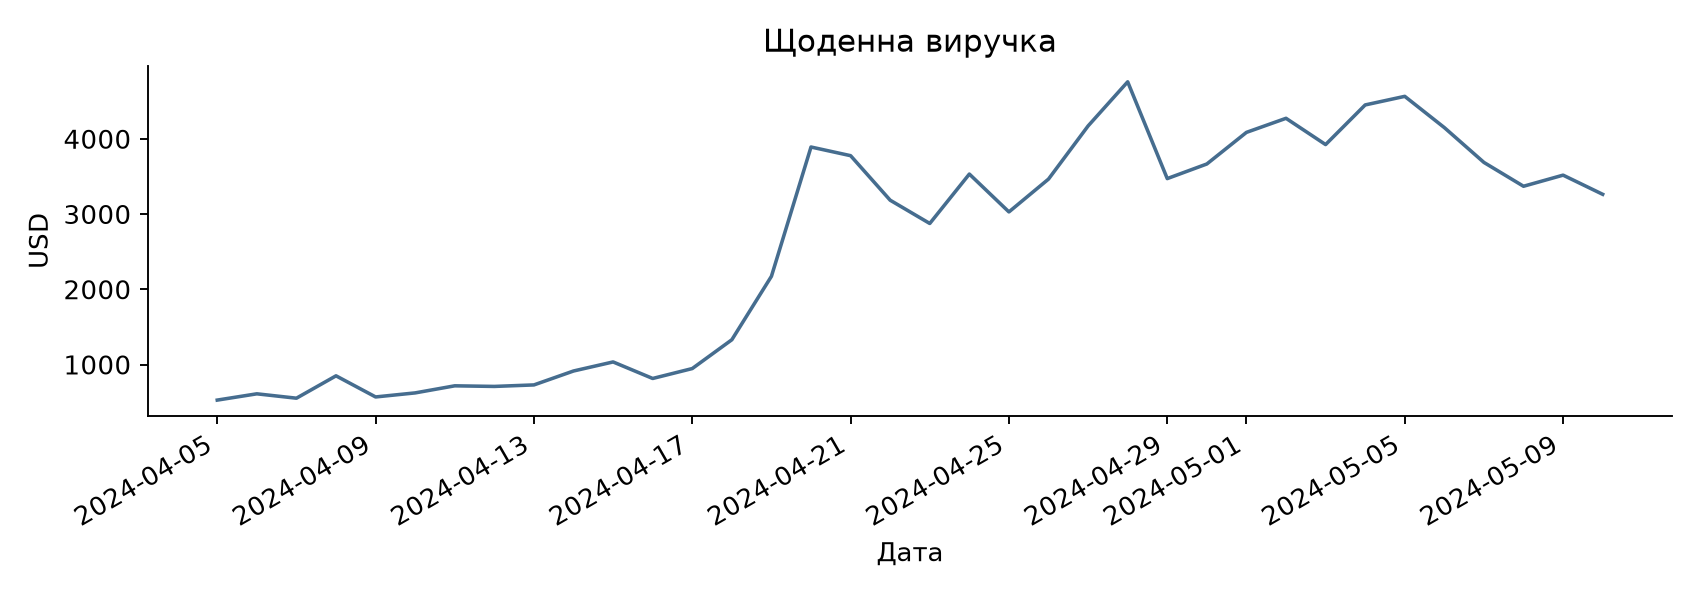

In [4]:
base = metrics(payments)
display(pd.DataFrame([base]).round(4))
assert base["revenue_usd"] == 92240.40
assert base["payments"] == 11159
assert base["paying_users"] == 7664
save_json(base, RESULTS / "metrics.json")
selected = payments.loc[payments.pay_dt.ge("2024-04-05") & payments.pay_dt.lt("2024-05-11")]
daily = selected.groupby(selected.pay_dt.dt.normalize()).amount_cents.sum().div(100)
daily = daily.reindex(pd.date_range("2024-04-05", "2024-05-10"), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(daily.index, daily.values, color="#466d8f")
ax.set(title="Щоденна виручка", ylabel="USD", xlabel="Дата")
ax.spines[["top", "right"]].set_visible(False)
fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(RESULTS / "daily_revenue.png", dpi=170); plt.close(fig)
display(Image(filename=str(RESULTS / "daily_revenue.png")))

## 4. Пояснення зміни метрики
Порівнюю **29.04–03.05** і **06.05–10.05**: по п’ять днів із понеділка до п’ятниці.
Функція підтримує виручку `revenue_usd` та кількість платежів `payments`.
Внесок сегмента — його нове значення мінус старе. Сума внесків у кожному окремому розрізі
має дорівнювати загальній зміні. Країни, платформи та типи покупок — альтернативні розрізи,
тому їхні внески між собою не додаються.

`contribution_pct = delta_segment / delta_total × 100`. При нульовій зміні частка не визначена.
Внески можуть бути від’ємними або більшими за сто відсотків, якщо сегменти компенсують один одного.

,metric,before_period,after_period,before,after,delta,change_pct,same_weekdays
0,revenue_usd,"[2024-04-29, 2024-05-03]","[2024-05-06, 2024-05-10]",19425.64,17991.01,-1434.63,-7.385239,True


Розріз: app


,segment,before,after,delta,contribution_pct
0,mobile,18119.79,17289.28,-830.51,57.89
1,desktop,937.34,554.07,-383.27,26.72
2,android,325.54,105.40,-220.14,15.34
3,ios,42.97,42.26,-0.71,0.05


Розріз: country_code


,segment,before,after,delta,contribution_pct
0,ZA,1560.74,1024.20,-536.54,37.40
1,UA,4262.65,4750.10,487.45,-33.98
2,US,2926.09,3412.57,486.48,-33.91
3,ES,1315.73,849.35,-466.38,32.51
4,GB,1072.62,677.79,-394.83,27.52
5,DO,606.91,288.57,-318.34,22.19
6,PE,485.91,330.56,-155.35,10.83
7,EC,140.44,280.64,140.20,-9.77


Розріз: feature_type_id


,segment,before,after,delta,contribution_pct
0,1,15887.79,14754.43,-1133.36,79.0
1,2,3537.85,3236.58,-301.27,21.0


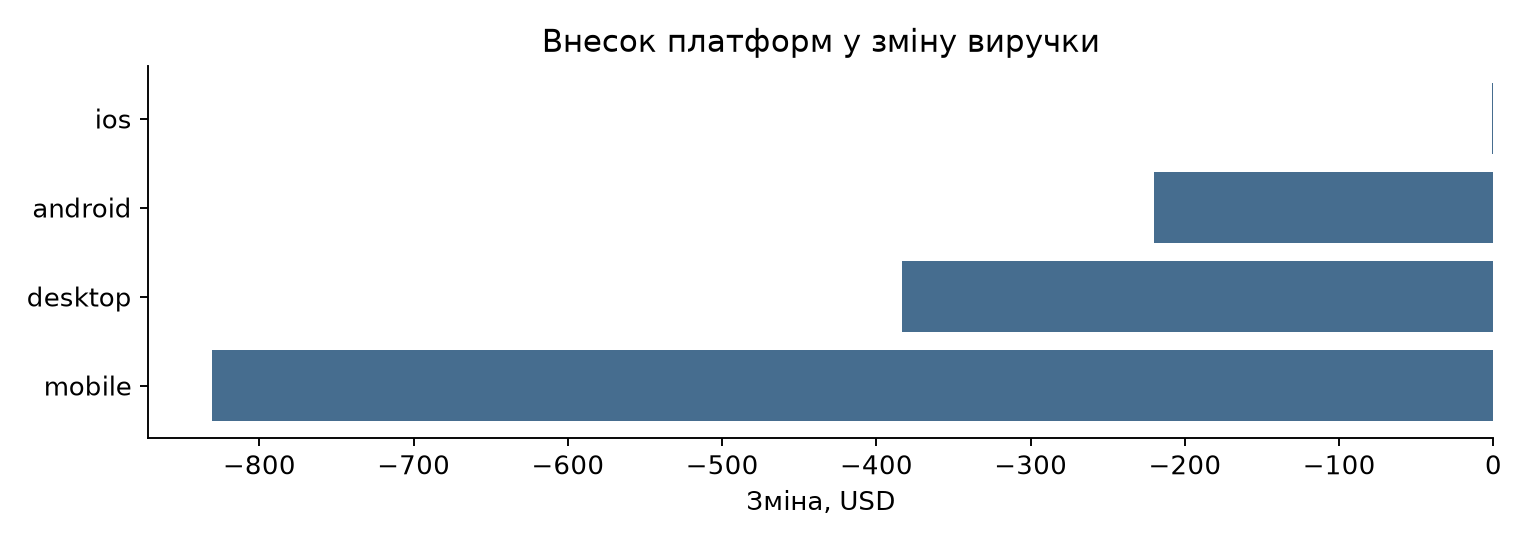

Модель: qwen2.5:7b | saved_validated

1. Зменшення загальної виручки
Спостереження: Виручка знизилася.
Гіпотеза / обмеження: Можливо, збільшилось число користувачів, які не робили покупок.
Перевірка: Порівняти кількість платників в обох періодах.
  [F011] revenue_usd: change_pct: -7.39 
  [F039] feature_type_id=1; revenue_usd: before: 15,887.79 
  [F042] feature_type_id=2; revenue_usd: before: 3,537.85 

2. Зменшення виручки для мобільного додатку
Спостереження: Виручка знизилася для мобільного додатку.
Гіпотеза / обмеження: Можливо, користувачі стали рідше використовувати мобільний додаток.
Перевірка: Порівняти кількість сесій або активності користувачів у мобільному додатку в обох періодах.
  [F014] app=mobile; revenue_usd: delta; зменшення: -830.51 
  [F026] country_code=ZA; revenue_usd: delta; зменшення: -536.54 
  [F039] feature_type_id=1; revenue_usd: before: 15,887.79 

3. Збільшення виручки для України
Спостереження: Виручка збільшилася для України.
Гіпотеза / обмеження: Можлив

In [5]:
BEFORE = ("2024-04-29", "2024-05-03")
AFTER = ("2024-05-06", "2024-05-10")
anomaly = explain_metric_change(payments, BEFORE, AFTER, metric="revenue_usd", client=client)
comparison = anomaly["comparison"]
display(pd.DataFrame([{k:v for k,v in comparison.items() if k != "breakdown"}]))
for dimension, table in comparison["breakdown"].items():
    print("Розріз:", dimension)
    display(table.head(8).round(2))
    assert abs(table.delta.sum() - comparison["delta"]) < 0.001
    table.to_csv(RESULTS / f"change_by_{dimension}.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 3.2))
table = comparison["breakdown"]["app"].sort_values("delta")
ax.barh(table.segment, table.delta, color="#466d8f")
ax.set(title="Внесок платформ у зміну виручки", xlabel="Зміна, USD")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(RESULTS / "platform_change.png", dpi=170); plt.close(fig)
display(Image(filename=str(RESULTS / "platform_change.png")))
print(format_analysis(anomaly["analysis"]))
save_json(anomaly["analysis"], RESULTS / f"anomaly_{MODE}.json")

Виручка зменшилась із **19 425,64 до 17 991,01 USD**, тобто на **1 434,63 USD (7,39%)**.
На mobile припадає **830,51 USD**, або **57,89%** цього зменшення. Це визначає сегмент для перевірки,
але не доводить технічну несправність чи зміну реклами. Нижче модель має запропонувати перевірювані припущення.

## 5. Генерація гіпотез
Очікую п’ять гіпотез. Кожна містить спостереження, припущення, спосіб перевірки й посилання на факти.
Кожне число у тексті перевіряється за вказаними фактами; функція `format_analysis` також показує точні значення окремо.
Наявність правильного ID ще не гарантує, що гіпотеза логічна — її потрібно прочитати й оцінити.

In [6]:
hypotheses = suggest_hypotheses(payments, comparison, client=client)
print(format_analysis(hypotheses))
save_json(hypotheses, RESULTS / f"hypotheses_{MODE}.json")

Модель: qwen2.5:7b | saved_validated

1. Зменшення виручки
Спостереження: Виручка знизилась.
Гіпотеза / обмеження: Можливо, збільшилось число користувачів, які не робили покупок.
Перевірка: Порівняти кількість платників в обох періодах.
  [F010] revenue_usd: delta; зменшення: -1,434.63 
  [F011] revenue_usd: change_pct: -7.39 

2. Зменшення виручки для мобільного застосунку
Спостереження: Виручка знизилась для мобільного застосунку.
Гіпотеза / обмеження: Можливо, користувачі стали рідше використовувати мобільний застосунок.
Перевірка: Порівняти кількість покупок у мобільному застосунку в обох періодах.
  [F012] app=mobile; revenue_usd: before: 18,119.79 
  [F013] app=mobile; revenue_usd: after: 17,289.28 

3. Збільшення виручки для України
Спостереження: Виручка збільшилася для України.
Гіпотеза / обмеження: Можливо, збільшилося число платників або середнє значення платежу у Україні.
Перевірка: Порівняти кількість платників та середню вартість покупки у Україні в обох періодах.
  [F025

**Моя перевірка гіпотез.** У пункті про Україну факт F025 стосується Південної Африки,
тому він зайвий. Правильне порівняння для України: 4 262,65 → 4 750,10 USD.
У четвертому пункті модель помилково назвала ES Італією. ES — Іспанія, її зміна становить −466,38 USD.
Також кілька пунктів повторюють одну ідею про зменшення числа покупців.

Після перевірки я сформулював п’ять напрямів дослідження:
1. Частина попередніх платників не повернулася: порівняти склад платників за user_id.
2. На mobile поменшало повторних покупок: порівняти платежі на одного платника.
3. Зросла частка дешевших покупок: порівняти розподіл amount_usd та типів покупок.
4. Спад у Південній Африці пов’язаний зі складом платників: порівняти нових і повторних покупців країни.
5. У типі покупки 1 зменшилася частота покупок: окремо зіставити їх кількість, платників і середній платіж.

Це мої уточнення після перегляду, а не дослівна відповідь LLM. Жодна з причин поки не доведена.

## 6. Короткий підсумок для продакт-менеджера
Три пункти: що відбулося, чому це важливо і що перевірити далі. Це чернетка аналітичного висновку;
рекомендації моделі потрібно зіставити з бізнес-контекстом.

In [7]:
summary = executive_summary(payments, comparison, client=client)
print(format_analysis(summary))
save_json(summary, RESULTS / f"summary_{MODE}.json")

Модель: qwen2.5:7b | saved_validated

1. Зменшення загальної виручки
Спостереження: Виручка знизилася.
Гіпотеза / обмеження: Можливо, збільшилось число платників, але середнє значення платежу зменшилося.
Перевірка: Порівняти кількість платників та середню вартість покупки перед та після періоду.
  [F010] revenue_usd: delta; зменшення: -1,434.63 
  [F011] revenue_usd: change_pct: -7.39 

2. Зменшення виручки з платників для мобільного застосунку
Спостереження: Виручка з платників для мобільного застосунку знизилася.
Гіпотеза / обмеження: Можливо, користувачі стали рідше використовувати мобільний застосунок.
Перевірка: Порівняти кількість сесій та активності користувачів у мобільному застосунку перед та після періоду.
  [F012] app=mobile; revenue_usd: before: 18,119.79 
  [F013] app=mobile; revenue_usd: after: 17,289.28 

3. Збільшення виручки з платників для України
Спостереження: Виручка з платників з України збільшилася.
Гіпотеза / обмеження: Можливо, це наслідок змін у курсі валюти а

**Моя оцінка підсумку.** У першому пункті модель припускає збільшення числа платників.
Це суперечить даним: їх стало 1 642 замість 1 730. Середній платіж теж трохи знизився — з 8,13 до 8,06 USD.
Тому це припущення я відхиляю. Перевірка сесій потребує додаткової таблиці, якої в цьому аналізі немає.
Пояснення через курс валют також не підтверджене: суми вже подані у USD, даних про конвертацію немає.

Мій короткий підсумок: виручка впала на 7,39%; найбільший внесок має mobile.
Платників і платежів поменшало. Наступний крок — перевірити повторні покупки та склад платників
у сегментах зі спадом. Для висновку про причини цих змін потрібні додаткові дані.

### Моя перевірка відповідей
У попередньому запуску Qwen2.5 модель написала, що виручка desktop зросла, хоча
таблиця показувала 937,34 → 554,07 USD. Таку інтерпретацію я відхилив.
Після цього додав до фактів напрямок зміни, округлив числа лише в контексті LLM
та прибрав дублювання повної JSON-схеми в тексті запиту. Первинні розрахунки не змінював.

Зменшення платежів або виручки ще не доводить зниження активності чи технічну помилку.
Гіпотези про ціни й поведінку користувачів потрібно перевіряти окремо.
Журнали з невдалими відповідями залишив у комплекті, щоб було видно реальний процес перевірки.

## 7. Перевірки та обмеження
Тести перевіряють розрахунки й обробку помилок. Відповіді у тестах JSON-валідатора створені вручну:
це контрольні приклади, а не результати мовної моделі. Реальні запити зберігаються окремо в `results/llm_runs`.

Код не виконує згенерований моделлю Python. JSON-схема обмежує формат, але не усуває всі галюцинації.
Перевіряються ID доказів і відповідність чисел значенням зазначених фактів; смисл, числа словами та причинність
не можуть бути повністю перевірені цим простим валідатором.

In [8]:
import unittest
suite = unittest.defaultTestLoader.discover(str(ROOT / "tests"))
test_result = unittest.TextTestRunner(verbosity=1).run(suite)
assert test_result.wasSuccessful(), "Є помилки в тестах."
print(f"Успішно: {test_result.testsRun} тестів.")

.

.

.

.

.

...

.

.

.

----------------------------------------------------------------------
Ran 22 tests in 0.955s

OK


Успішно: 22 тестів.


In [9]:
from assistant import validate_response
invalid = {"items": [{"title":"Перевірка", "observation":"Виручка становить 999 USD.",
                      "hypothesis":"Можлива зміна попиту.", "check":"Перевірити платежі.",
                      "evidence_ids":["F001"]}]}
try:
    validate_response(invalid, {"F001":{"label":"Виручка", "value":42, "unit":"USD"}}, 1)
except ValueError as error:
    print("Навмисно помилкову відповідь відхилено:", error)

Навмисно помилкову відповідь відхилено: Число 999 у полі observation не підтверджене evidence_ids. Прибери його або вкажи правильне джерело; не обчислюй нових чисел.


## 8. Результат запуску
За `MODE="live"` чотири відповіді мають статус `live_validated`; за `saved` — `saved_validated`.
Збережений режим звіряє модель, факти й системний промпт із журналом справжнього запуску.
Якщо модель не відповіла
або JSON не пройшов повторну перевірку, комірка покаже помилку, а журнал збереже причину.
Режим без LLM не є повністю виконаною AI-демонстрацією.

Після успішного запуску збережи ноутбук із результатами. У `prompts.md` описано промпти й їхню зміну,
у README — запуск і склад файлів. Під час підготовки коду й оформлення використано допомогу OpenAI Codex.

In [10]:
statuses = {"eda":eda["analysis"]["status"], "anomaly":anomaly["analysis"]["status"],
            "hypotheses":hypotheses["status"], "summary":summary["status"]}
display(pd.DataFrame(statuses.items(), columns=["Функція", "Статус"]))
if MODE in {"live", "saved"}:
    expected = "live_validated" if MODE == "live" else "saved_validated"
    assert all(status == expected for status in statuses.values())
    print("Чотири відповіді перевірено. Переглянь зміст відповідей і збережи ноутбук.")
else:
    print("Розрахунки перевірено. Для AI-демо встанови MODE='live' та виконай Restart Kernel and Run All.")

,Функція,Статус
0,eda,saved_validated
1,anomaly,saved_validated
2,hypotheses,saved_validated
3,summary,saved_validated


Чотири відповіді перевірено. Переглянь зміст відповідей і збережи ноутбук.
